# Units: What GATE Writes And What An Analysis Reads

**Version**: 1

**Last modified**: 2026-10-12

**Compatible with opengate-gate-tree version:** 0.6.0

**Author**: Mateusz Jakub Bała

## About

GATE writes every quantity in the units Geant4 works in: energy in MeV, length
in mm, time in s. An analysis reads a spectrum in keV, describes a scanner in
cm, and quotes a time in ns. This notebook converts the columns of a real
"Hits" tree between the two, and uses the result to check the file against
two things known in advance: the speed of light, and the lifetime of
ortho-positronium.

It is also about what a conversion does not do: it never changes the data it
was given, and nothing carries a unit around for you.

## What will you learn from this notebook

- which unit each kind of quantity of a "Hits" tree is written in, and how to
  ask the package
- how to convert a number, an array or a column, and what comes back
- how to put a conversion in the middle of a selection
- why every conversion computes in `float64`, and what the extra digits it
  prints do and do not mean
- why a file written by the package still holds the numbers GATE wrote

## Tutorial

Every step below is a line of text, the code that does what the line says, and
a word about the answer where the answer needs one.

In [1]:
from tools import environment, paths, plotting

plotting.use_tutorial_style()
print(environment.describe())

opengate-gate-tree: 0.5.0
python: 3.14.5
run on: 2026-10-12


The header of this notebook states the version it was written for; the line
above states the version it just ran against. If they differ, the notebook may
still be right — but nobody has checked it against what is installed.

Two paths: the one place this notebook may write, and the example file it
reads. What the file holds is described in
[`../data/README.md`](../data/README.md).

In [2]:
output = paths.output_dir("tutorial-12-units")
example_input = paths.input_example("positronium-source-all-variants.root")

In [3]:
import numpy as np
import pandas as pd

from opengate_gate_tree import (
    GATE_UNITS,
    DecayType,
    GammaType,
    GateTree,
    MeV_to_keV,
    OutputFileFormat,
    SourceType,
    TreeData,
    read_tree,
    write_tree,
)

hits = read_tree(
    example_input,
    GateTree.HITS,
    [
        "runID",
        "eventID",
        "trackID",
        "edep",
        "time",
        "trackLocalTime",
        "trackLength",
        "sourceType",
        "decayType",
        "gammaType",
    ],
)
frame = hits.to_dataframe()
frame.head()

,runID,eventID,trackID,edep,time,trackLocalTime,trackLength,sourceType,decayType,gammaType
0,0,0,2,0.094538,0.000011,6.675236e-10,200.118546,2,1,2
1,0,0,2,0.416461,0.000011,6.698628e-10,200.819824,2,1,2
2,0,0,1,0.220403,0.000011,6.770235e-10,202.966537,2,1,2
3,0,0,1,0.290596,0.000011,6.794738e-10,203.701141,2,1,2
4,0,1,2,0.132729,0.000039,6.841307e-10,205.097214,4,1,2


### What GATE Writes

`GATE_UNITS` names the unit of each kind of quantity the conversions are about.
It is where the conversion of a branch starts: `edep` is an energy, so it is in
MeV; `trackLength` is a length, so mm; `time` is a time, so s.

In [4]:
dict(GATE_UNITS)

{'energy': 'MeV', 'length': 'mm', 'time': 's'}

The conversions come in four families, each closed — every unit of a family
reaches every other one, in both directions:

| Family | Units | Conversions |
| --- | --- | --- |
| energy | MeV, keV | `MeV_to_keV`, `keV_to_MeV` |
| length | mm, cm, m | `mm_to_cm`, `cm_to_mm`, `mm_to_m`, `m_to_mm`, `cm_to_m`, `m_to_cm` |
| time | s, ms, ns | `s_to_ms`, `ms_to_s`, `s_to_ns`, `ns_to_s`, `ms_to_ns`, `ns_to_ms` |
| angle | rad, deg | `rad_to_deg`, `deg_to_rad` |

A unit symbol keeps its capital letters, `MeV_to_keV`, because `MeV` and `meV`
are different units.

### What A Conversion Answers With

The kind it was given. A number comes back as a number:

In [5]:
MeV_to_keV(0.511)

511.0

A column comes back as a column, with its index and its name, so it can stand
beside the frame it came from. On a column, the conversions are also reached
through the `gate` namespace the package registers:

In [6]:
energies = frame["edep"].gate.MeV_to_keV()
energies.head()

0     94.537668
1    416.461229
2    220.402807
3    290.596098
4    132.728606
Name: edep, dtype: float64

Look at the digits. The file holds `edep` as `float32`, and the conversion
computes in `float64`:

In [7]:
frame["edep"].dtype, energies.dtype

(dtype('float32'), dtype('float64'))

In [8]:
frame["edep"].iloc[0], energies.iloc[0]

(np.float32(0.09453767), np.float64(94.53766793012619))

`0.09453767` MeV became `94.53766793012619` keV, not `94.53767`. The extra
digits are not precision gained: they are the `float32` number GATE stored,
read exactly in `float64` and multiplied by 1000. A `float32` carries about
seven significant digits, and only those mean anything.

### A Spectrum In keV

The energy deposited per hit, read in keV. The bins are 20 keV wide over
0–1400 keV.

<Axes: title={'center': 'Energy deposited per hit'}, xlabel='energy deposited [keV]', ylabel='counts / 20 keV'>

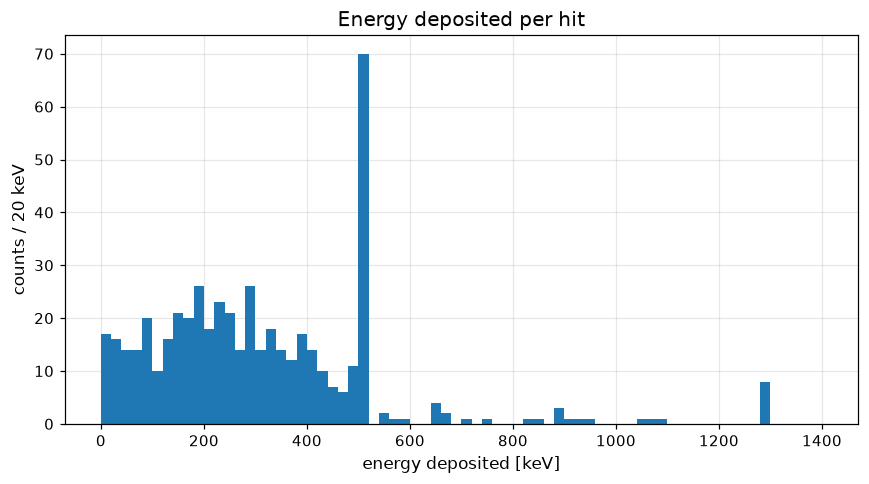

In [9]:
plotting.plot_hist_1d(
    energies,
    xrange=(0.0, 1400.0),
    xbins=70,
    xtitle="energy deposited [keV]",
    ytitle="counts / 20 keV",
    title="Energy deposited per hit",
)

Read in keV, the edge of the annihilation gammas falls where it is expected,
at 511 keV. Every hit above it belongs to a prompt gamma:

In [10]:
frame.loc[energies > 511.0, "gammaType"].value_counts().rename(
    index=lambda value: GammaType(value).name
)

gammaType
PROMPT    31
Name: count, dtype: int64

### Lengths

`trackLength` is how far the particle had travelled when the hit happened, in
mm. The detector of this scene is a spherical shell whose inside is 200 mm from
the source, so in cm:

In [11]:
frame["trackLength"].gate.mm_to_cm().describe()

count    500.000000
mean      20.773244
std        0.862142
min       20.000243
25%       20.169604
50%       20.526481
75%       21.077312
max       27.139111
Name: trackLength, dtype: float64

No hit is closer than 20 cm: a gamma has to cross the empty inside of the
shell before it can deposit anything.

### Times, And A Check On The Units

`trackLocalTime` is the time since the track started, in s. In ns, the numbers
are of a size one can read:

In [12]:
flight_time = frame["trackLocalTime"].gate.s_to_ns()
flight_time.describe()

count    500.000000
mean       0.692921
std        0.028758
min        0.667136
25%        0.672786
50%        0.684690
75%        0.703063
max        0.905263
Name: trackLocalTime, dtype: float64

A gamma covers about 200 mm in about 0.7 ns. Dividing the two, in mm and ns,
gives a speed in mm/ns — and the speed of a gamma is the speed of light,
299.792458 mm/ns:

In [13]:
speed = frame["trackLength"] / flight_time
speed.describe()

count    500.000000
mean     299.792458
std        0.000006
min      299.792447
25%      299.792452
50%      299.792457
75%      299.792463
max      299.792469
dtype: float64

Every one of the 500 hits gives between 299.79245 and 299.79247 mm/ns. The
file is consistent with itself, and the units are the ones `GATE_UNITS` says.

### The Lifetime Of Ortho-Positronium

`time` is when the hit happened, counted from the start of the run. The hits of
one decay belong to one event — the pair `(runID, eventID)` — so the time of
each hit after the first hit of its event says how long the decay took to show
itself. In ns:

In [14]:
first_hit_time = frame.groupby(["runID", "eventID"])["time"].transform("min")
delay = (frame["time"] - first_hit_time).gate.s_to_ns()

delay.groupby(frame["sourceType"]).max().rename(index=lambda value: SourceType(value).name)

sourceType
NOT_DEFINED              0.065151
PARA_POSITRONIUM         0.512477
ORTHO_POSITRONIUM      586.834753
DIRECT_ANNIHILATION      0.067598
Name: time, dtype: float64

Every kind of source shows its hits within a fraction of a nanosecond — the
time a gamma needs to cross the shell — except ortho-positronium, whose events
spread over hundreds of nanoseconds. The prompt gamma is emitted at once, and
the annihilation gammas only when the ortho-positronium decays — on the scale
of its lifetime, about 142 ns in vacuum. The lifetime this simulation was
configured with is not recorded in the file, so the plot below shows the scale,
not a measurement of it.

The ortho-positronium events that emitted a prompt gamma show it best: in each
of the 19 such events in this file the prompt gamma was detected, within 0.1 ns
of the first hit, so the time after the first hit is the time after the prompt
gamma. Drawn for the annihilation gammas:

<Axes: title={'center': 'Annihilation gammas of ortho-positronium, after the prompt gamma'}, xlabel='time after the first hit of the event [ns]', ylabel='counts / 20 ns'>

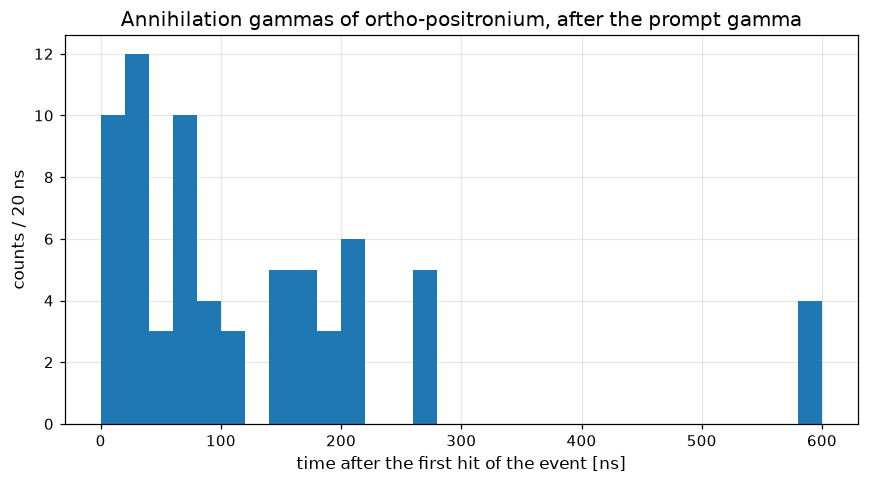

In [15]:
delayed = (
    (frame["sourceType"] == SourceType.ORTHO_POSITRONIUM)
    & (frame["decayType"] == DecayType.DEEXCITATION)
    & (frame["gammaType"] == GammaType.ANNIHILATION)
)

plotting.plot_hist_1d(
    delay[delayed],
    xrange=(0.0, 600.0),
    xbins=30,
    xtitle="time after the first hit of the event [ns]",
    ytitle="counts / 20 ns",
    title="Annihilation gammas of ortho-positronium, after the prompt gamma",
)

In seconds the same numbers would have been between 0 and 6·10⁻⁷ — correct,
and impossible to read off an axis.

### Why Every Conversion Computes In float64

A `float32` has a 24-bit mantissa, so the numbers it can hold get sparser as
they grow. Sixty seconds read in nanoseconds is 6·10¹⁰, and the distance from
there to the next `float32` is:

In [16]:
sixty_seconds_in_ns = np.float32(60.0) * np.float32(1e9)

np.spacing(sixty_seconds_in_ns), np.spacing(np.float64(6e10))

(np.float32(4096.0), np.float64(7.62939453125e-06))

4096 ns: a time a minute into a run, converted in `float32`, could only be told
to the nearest four microseconds — far coarser than the delays above. In
`float64` the grid is 8·10⁻⁶ ns. That is why a conversion answers in `float64`
whatever came in, including the `float32` columns of a GATE file.

### A Conversion In A Chain

Selection and conversion are both on the `gate` namespace, so they read as one
line. The energies between 200 and 400 keV, selected in the unit of the file
and read in keV:

In [17]:
middle = frame["edep"].gate.in_range(0.2, 0.4).gate.MeV_to_keV()
middle.head()

2     220.402807
3     290.596098
7     273.779750
11    366.261542
12    381.892771
Name: edep, dtype: float64

The selection keeps the rows it keeps, and the conversion keeps their index:
the first rows are 2, 3, 7 and so on, the rows of the frame they came from. So
the result goes back beside the frame by the index alone:

In [18]:
frame.join(middle.rename("edep_keV")).dropna(subset=["edep_keV"]).head()

,runID,eventID,trackID,edep,time,trackLocalTime,trackLength,sourceType,decayType,gammaType,edep_keV
2,0,0,1,0.220403,0.000011,6.770235e-10,202.966537,2,1,2,220.402807
3,0,0,1,0.290596,0.000011,6.794738e-10,203.701141,2,1,2,290.596098
7,0,1,2,0.273780,0.000039,6.937886e-10,207.992599,4,1,2,273.779750
11,0,2,2,0.366262,0.000049,6.946359e-10,208.246613,3,1,2,366.261542
12,0,2,1,0.381893,0.000049,6.723716e-10,201.571930,3,1,2,381.892771


A missing value stays missing through a conversion, so the rows `join` left
empty did not need converting first.

In [19]:
MeV_to_keV(pd.Series([0.511, np.nan], name="edep"))

0    511.0
1      NaN
Name: edep, dtype: float64

### Angles

The fourth family. Every angle the package computes is in radians, as in NumPy;
degrees are a reading of it, usually the last step before a plot:

In [20]:
pd.Series([0.0, np.pi / 2, np.pi]).gate.rad_to_deg()

0      0.0
1     90.0
2    180.0
dtype: float64

### What A File Holds

A conversion answers with new values and leaves its argument alone. The
`TreeData` the frame was taken from still holds MeV:

In [21]:
hits["edep"].max()

np.float32(1.3)

So a file written from it holds the numbers as GATE wrote them, and an analysis
reading that file finds MeV, mm and s, as in any GATE file:

In [22]:
written = write_tree(hits, output / "hits.root", OutputFileFormat.ROOT)
read_tree(written, GateTree.HITS, validate=False)["edep"].max()

np.float32(1.3)

There is no unit system behind this: nothing carries its unit along, and a file
records numbers, not units. A frame holding converted values writes them as they
are, so name such a column after its unit — whoever reads the file next has no
other way of knowing:

In [23]:
in_kev = frame[["eventID", "edep"]].assign(edep_keV=energies).drop(columns="edep")

written_kev = write_tree(
    TreeData.from_dataframe(GateTree.HITS, in_kev),
    output / "hits-kev.root",
    OutputFileFormat.ROOT,
)
read_tree(written_kev, GateTree.HITS, validate=False).to_dataframe().head(3)

,eventID,edep_keV
0,0,94.537668
1,0,416.461229
2,0,220.402807


## Summary

A "Hits" tree is written in MeV, mm and s, and `GATE_UNITS` says so in code.
The conversions turn a number, an array or a column into the unit an analysis
reads, in `float64`, keeping the index so that they fit into a chain — and here
they were enough to check the speed of light against the file and to show the
scale of the ortho-positronium lifetime. They never change the data they were
given, so a file written by the package still holds the numbers GATE wrote.

## Bibliography

- [Units](https://opengate-gate-tree.readthedocs.io/en/latest/guide/units.html)
  — the units GATE writes, the four families and why they compute in `float64`
- [Filtering And Selecting](https://opengate-gate-tree.readthedocs.io/en/latest/guide/filtering.html)
  — `in_range`, the first half of the chain above
- [Event Identifiers](https://opengate-gate-tree.readthedocs.io/en/latest/guide/events.html)
  — why an event is the pair `(runID, eventID)`
- [PositroniumSource Data](https://opengate-gate-tree.readthedocs.io/en/latest/guide/positronium.html)
  — what the values of `sourceType` and `gammaType` mean
- [Exporting Files](https://opengate-gate-tree.readthedocs.io/en/latest/guide/export.html)
  — what a written file holds
- R. S. Vallery, P. W. Zitzewitz, D. W. Gidley, *Resolution of the
  Orthopositronium-Lifetime Puzzle*, Phys. Rev. Lett. 90, 203402 (2003) — the
  decay rate of ortho-positronium in vacuum, 7.04 µs⁻¹, that is about 142 ns

## Changelog

- v1: written.